# Lesson 07 · Empirical Bayesian hierarchical modeling

**Source:** *Introduction to Empirical Bayes: Examples from Baseball Statistics*, David Robinson (2017), Chapter 8 (pp. 65–74)

**Question:** Two batters each have 30 hits in 100 at-bats; one bats left-handed and one right-handed. Who's more likely the better hitter, and does the answer depend on the era?

**Goal:** Extend beta-binomial regression with handedness, a spline over time and an interaction, and see how each changes the prior and the posterior.

**Contents**

1. Setup
2. Left- and right-handed batters
3. Batting averages over time
4. A spline for year
5. Interaction: has the lefty advantage changed?
6. Posteriors for the 30/100 batters
7. Uncertainty in the hyperparameters

**Tags:** `hierarchical-models` `beta-binomial-regression` `splines` `interactions` `handedness` `hyperparameter-uncertainty`

**Before you start:** Lesson 06. You'll need your `fit_bb_regression` function: paste it below the setup cell or import it from `my_eb.py`.

*How this notebook works:* each **Your turn** prompt is followed by an empty cell for your code. **Check** boxes give values to compare against; they come from the book, and your numbers can differ slightly because the Lahman data now runs through more recent seasons. **Reflect** prompts are for short written answers. Every prompt is numbered *lesson.section.question* (for example **2.3.1**), so you can refer to it; empty code cells and answer cells carry the same number.

In [2]:
# --- Setup: run this cell first ------------------------------------------
# Windows + conda: put the environment's DLL folders on PATH, so plotting
# can't crash the kernel when Jupyter wasn't started from the activated env.
import os, sys
for sub in ["Library\\mingw-w64\\bin", "Library\\usr\\bin", "Library\\bin", "Scripts", "bin"]:
    p = os.path.join(sys.prefix, sub)
    if os.path.isdir(p) and p not in os.environ["PATH"]:
        os.environ["PATH"] = p + os.pathsep + os.environ["PATH"]

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
from scipy import stats, optimize, special

import eb_data   # helpers in this folder: loading the Lahman data, saving results

rng = np.random.default_rng(2017)
pd.set_option("display.precision", 4)
plt.rcParams["figure.figsize"] = (7, 4)
print(f"numpy {np.__version__} | pandas {pd.__version__} | scipy {scipy.__version__}")

career = eb_data.career(pitcher_rule=3, extra=True)   # adds `year` (mean season) and `bats`
print(f"{len(career):,} players")
print(career["bats"].value_counts(dropna=False))

# Splines: patsy's natural cubic spline cr() is closest to R's ns(). If patsy
# is missing, install it into the pymc env from an Anaconda Prompt:
#     conda install -n pymc -c conda-forge patsy
# or build a basis with scipy.interpolate.BSpline instead.
try:
    import patsy
    print("patsy", patsy.__version__)
except ImportError:
    print("patsy not installed (see note above)")

numpy 2.5.3 | pandas 3.0.6 | scipy 1.18.1
13,446 players
bats
R      6991
L      3474
NaN    2002
B       979
Name: count, dtype: int64
patsy 1.0.3


## 1. Setup

**7.1.1 · Your turn.** Bring in your `fit_bb_regression` from Lesson 06. Refit the log(AB) model to confirm it works here.

In [3]:
# 7.1.1 · Your code here
def to_alpha_beta(mu, sigma):
    alpha = mu / sigma
    beta = ((1 - mu) / sigma)
    return alpha, beta

def bb_reg_neg_log_lik(params, H, AB, X):
    [*b, log_sigma] = params
    mu = np.clip((X @ b), 1e-6, (1-1e-6))
    sigma = np.exp(log_sigma)
    alpha = mu / sigma
    beta = ((1 - mu)/sigma)
    return -stats.betabinom.logpmf(H, AB, alpha, beta).sum()

def fit_bb_regression(H, AB, X, start = None):
    if start is None:
        start = [0.15, 0.01, *([0] * (X.shape[1] - 2)), -6]
    res = optimize.minimize(bb_reg_neg_log_lik, x0 = start, args = (H, AB, X), method = "L-BFGS-B")
    coeffs = res.x[:-1]
    sigfit = res.x[-1]
    return *coeffs, np.exp(sigfit)

X = np.column_stack((np.full(len(career), 1), np.log(career.AB)))
mu0_fit, muAB_fit, sig_fit = fit_bb_regression(career.H, career.AB, X)
print(mu0_fit, muAB_fit, sig_fit)

0.14842999322124256 0.014528019575642842 0.0021850478502553807


## 2. Left- and right-handed batters

`bats` is L, R or B (both: switch hitters). Players with missing handedness, mostly from the early years, are dropped for this part.

**7.2.1 · Your turn.** How many players are L, R, B and missing? About 9 in 10 people in the general population are right-handed. How does baseball compare, and what might that suggest?

In [5]:
# 7.2.1 · Your code here
hands = ['L', 'R', 'B']
counts = [0, 0, 0]
missing = 0
for i, (hand, count) in enumerate(zip(hands, counts)):
    num = (career['bats'] == hand).sum()
    counts[i] += int(num)

print(counts)
missing = len(career) - sum(counts)
ratio = (counts[1] / sum(counts))
print(f"Lefties: {counts[0]}, Righties {counts[1]}, Switches: {counts[2]}, Missing: {missing}. Ratio of righties: = {ratio}")

[3474, 6991, 979]
Lefties: 3474, Righties 6991, Switches: 979, Missing: 2002. Ratio of righties: = 0.6108878014680181


A lower ratio of right handed batters, meaning a higher proportion of left handed batters, consistent with the notion that managers and teams might prefer hiring left handed batters in a game with predominantly right handed pitchers.

**7.2.2 · Your turn.** Drop missing `bats`. Build `X` with an intercept, `log(AB)`, `is_B` and `is_L`, so that right-handed is the baseline, and fit.

In [6]:
# 7.2.2 · Your code here
career_bats = career.dropna(subset=['bats'])
career_bats.head()
len(career_bats) == len(career) - missing

X_bats = np.column_stack((np.full(len(career_bats), 1), 
                          np.log(career_bats.AB), 
                          (career_bats['bats'] == 'B').astype(int), 
                          (career_bats['bats'] == 'L').astype(int)))
assert((sum(X_bats[:,2]) == counts[2]) & (sum(X_bats[:,3]) == counts[0])) # check all counts are correct

mu0_bats, muAB_bats, muB_bats, muL_bats, sig_bats = fit_bb_regression(career_bats.H, career_bats.AB, X_bats)
fits = [mu0_bats, muAB_bats, muB_bats, muL_bats, sig_bats]
print(fits)

[np.float64(0.14367474651331344), np.float64(0.014775997310533398), np.float64(-0.0012853317308329924), np.float64(0.009018810937698308), np.float64(0.002029871499797997)]


> **Check:** lefty ≈ +0.010, switch ≈ −0.001 (not distinguishable from 0), log(AB) ≈ 0.0152.

**7.2.3 · Your turn.** Plot the prior for L, R and B batters at AB = 1,000. Then, for a lefty and a righty who both hit 30%, plot the posteriors at AB = 10, 100, 1,000 and 10,000 (a 2×2 grid).

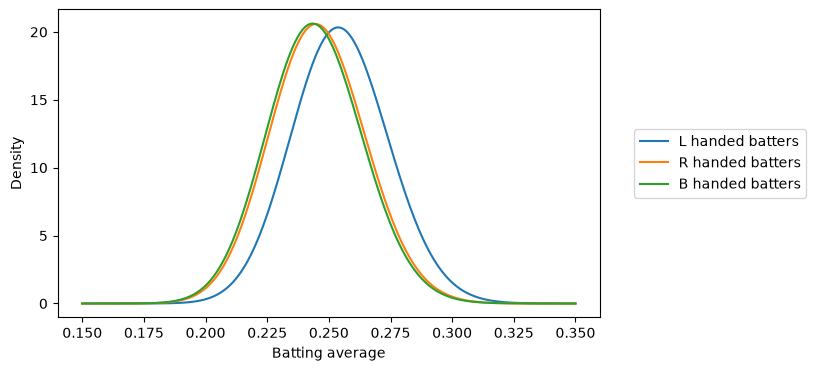

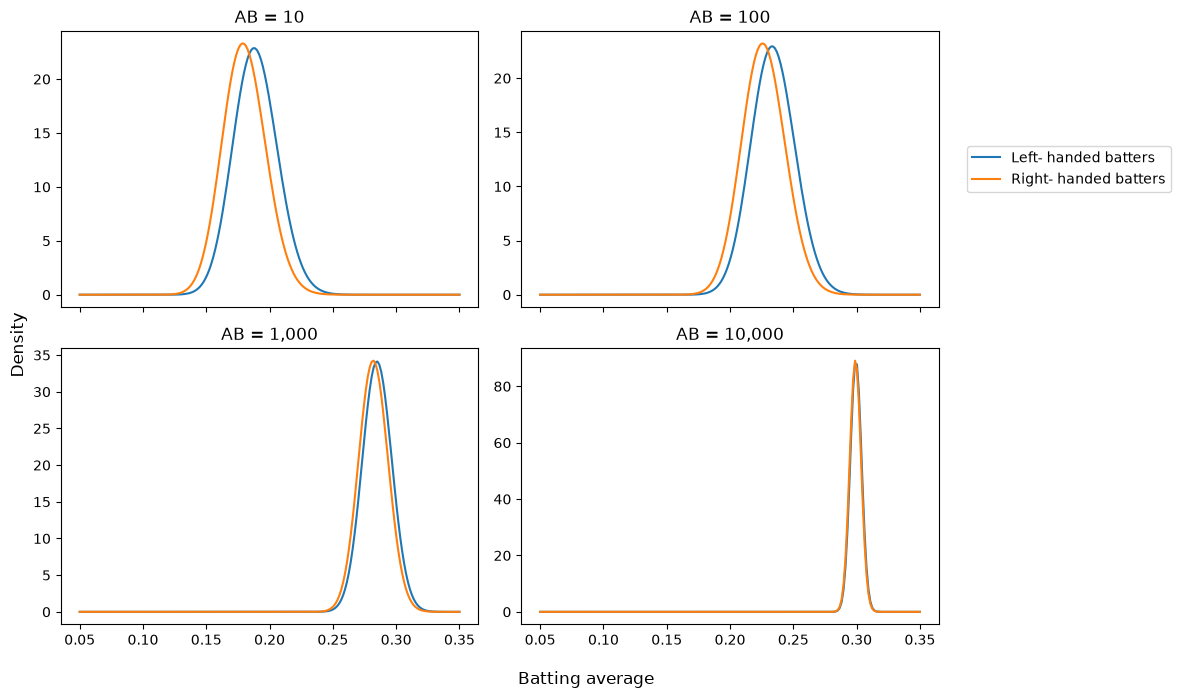

In [7]:
# 7.2.3 · Your code here

x = np.linspace(0.15, 0.35, 200)
mus = [muL_bats, 0, muB_bats]
for (hand, mu) in zip(hands, mus):
    mui_bats = mu0_bats + (muAB_bats * np.log(1000)) + mu 
    alpha, beta = to_alpha_beta(mui_bats, sig_bats)
    plt.plot(x, stats.beta(alpha,beta).pdf(x), label = f"{hand} handed batters")
plt.xlabel('Batting average')
plt.ylabel('Density')
plt.legend(bbox_to_anchor=(1.05, 0.5), loc="center left")
plt.show() 
        
ABs = [[10, 100], 
       [1000, 10000]]

fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex = True)
x = np.linspace(0.05, 0.35, 200)
for (row, col), AB in np.ndenumerate(ABs):
    for (hand, mu_hand) in zip(['Left', 'Right'], [muL_bats, 0]):
        mui = mu0_bats + (muAB_bats * np.log(AB)) + mu_hand
        a0, b0 = to_alpha_beta(mui, sig_bats)
        alpha1 = a0 + (0.3 * AB)
        beta1 = b0 + 0.7 * AB
        axes[row, col].plot(x, stats.beta(alpha1, beta1).pdf(x), label = f"{hand}- handed batters")
        axes[row, col].set_title(f"AB = {AB:,}")
axes[0, 1].legend(bbox_to_anchor=(1.05, 0.5), loc="center left")
fig.supxlabel('Batting average')
fig.supylabel('Density')
plt.tight_layout()
plt.show() 


**7.2.4 · Reflect.** Why do the left and right posteriors converge as AB grows?

*7.2.4 · Your answer:*
 

## 3. Batting averages over time

**7.3.1 · Your turn.** Make a box plot of raw averages by decade (use `year`, the mean season of a player's career; keep AB ≥ 500 to reduce noise).

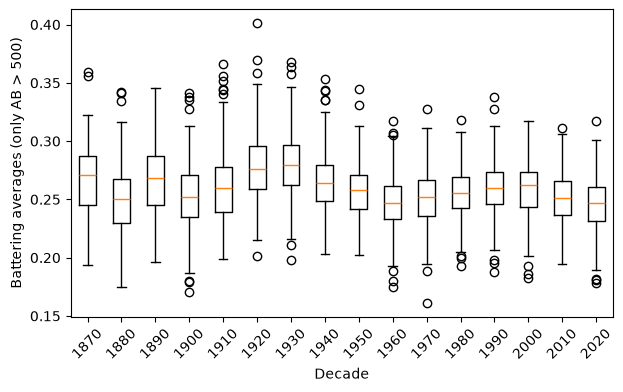

In [9]:
# 7.3.1 · Your code here
career_500 = career[career.AB >= 500]

grouped = career_500.groupby((career_500['year'] // 10).astype(int) * 10)['average']

data = [group.values for name, group in grouped]
labels = list(grouped.groups.keys())
plt.boxplot(data, tick_labels = labels)
plt.xticks(rotation=45)
plt.xlabel('Decade')
plt.ylabel('Battering averages (only AB > 500)')
plt.show()

**7.3.2 · Reflect.** Does a straight line in year look reasonable? What would you use instead?

*7.3.2 · Your answer:*
We probably could do better than a straight line. There are several inflections in the data which would be lost in fitting a straight line, especially since typically the dispersion of batting averages appears relatively tight (both a qualitative statement from working through several notebooks, as well as the objective observation, that some medians in some years are at the 25th or 75th quartiles of other years), so these undulations are likely real fluctuations we'd like to capture, with splines, or higher order polynomials.

## 4. A spline for year

The book uses a natural cubic spline with 5 degrees of freedom. With patsy, `patsy.dmatrix("cr(year, df=5) - 1", career)` builds the basis. The `- 1` removes the intercept, because the spline columns already span a constant. Building B-spline bases by hand works too; notebook 07 of Cardprice, a separate card-price project not included here, does it that way.

**7.4.1 · Your turn.** Build `X = [spline(year) | is_B | is_L | log(AB)]` (no separate intercept) and fit. Store the fitted coefficients.

In [28]:
# 7.4.1 · Your code here
career_bats['is_B'] = (career_bats['bats'] == 'B').astype(int) 
career_bats['is_L'] = (career_bats['bats'] == 'L').astype(int)

d = patsy.dmatrix("cr(year, df=5) + is_B + is_L + np.log(AB) - 1", career_bats)
X_spline = np.asarray(d)
spline_fit = fit_bb_regression(career_bats.H, career_bats.AB, X_spline, start = [*[0.15]*5, 0, 0, 0.01, -6])
spline_fit

(np.float64(0.12058862632236463),
 np.float64(0.15440664305829413),
 np.float64(0.13560244307856778),
 np.float64(0.137583433171488),
 np.float64(0.1305593304075697),
 np.float64(0.0005090168544235367),
 np.float64(0.009191236615630606),
 np.float64(0.015175584256243154),
 np.float64(0.0017226656854864386))

**7.4.2 · Your turn.** For a hypothetical player with AB = 1,000, plot the prior median and the 2.5% and 97.5% quantiles against year (1880–2015), one line and band for L and one for R.

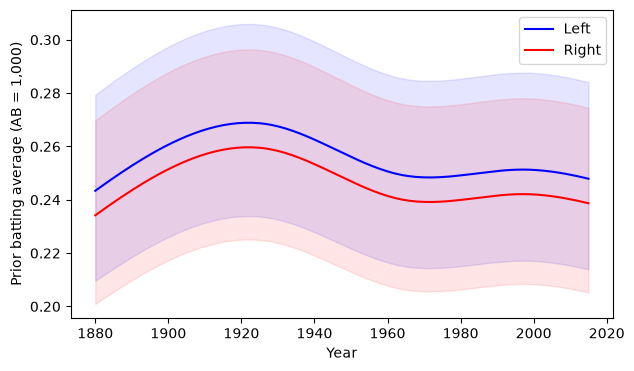

In [29]:
# 7.4.2 · Your code here
yrs = np.arange(1880, 2016, 1)
lefties = pd.DataFrame({
    'year' : yrs, 
    'AB' : 1000,
    'is_B' : 0,
    'is_L' : 1})
righties = lefties.copy()
righties['is_L'] = 0

L = np.asarray(patsy.build_design_matrices([d.design_info], lefties)[0])
R = np.asarray(patsy.build_design_matrices([d.design_info], righties)[0])

for side, color, hand in zip([L, R], ['blue', 'red'], ["Left", "Right"]):
    m = side @ spline_fit[0:-1]
    aside, bside = to_alpha_beta(m, spline_fit[-1])
    low = stats.beta(aside, bside).ppf(0.025)
    high = stats.beta(aside, bside).ppf(0.975)
    plt.plot(yrs, stats.beta(aside, bside).ppf(0.5), color = color, label = hand)
    plt.fill_between(yrs, low, high, color=color, alpha=0.1)
plt.legend()
plt.xlabel("Year")
plt.ylabel("Prior batting average (AB = 1,000)")
plt.show()

## 5. Interaction: has the lefty advantage changed?

**7.5.1 · Your turn.** Add interaction columns (each spline column × `is_L`, and × `is_B`), refit, and redraw the plot.

In [30]:
# 7.5.1 · Your code here
e = patsy.dmatrix("cr(year, df=5) + cr(year, df=5):is_L + cr(year, df=5):is_B + np.log(AB) - 1", career_bats)
X_spline2 = np.asarray(e)
spline_fit2 = fit_bb_regression(career_bats.H, career_bats.AB, X_spline2, start = [*[0.15]*5, *[0]*10, 0.01, -6])
spline_fit2

(np.float64(0.11957063270868473),
 np.float64(0.15162780585185567),
 np.float64(0.13680979416598377),
 np.float64(0.13918493564529863),
 np.float64(0.13517687570234896),
 np.float64(0.01698473665159889),
 np.float64(0.0180115564672557),
 np.float64(0.007136287841632963),
 np.float64(0.005048523453011954),
 np.float64(-0.001714928199963803),
 np.float64(-0.006392277919883221),
 np.float64(0.005121493219251953),
 np.float64(-0.0035512517346037178),
 np.float64(0.000205194912059617),
 np.float64(-0.004652183203540837),
 np.float64(0.015132091352890786),
 np.float64(0.0016721716434276441))

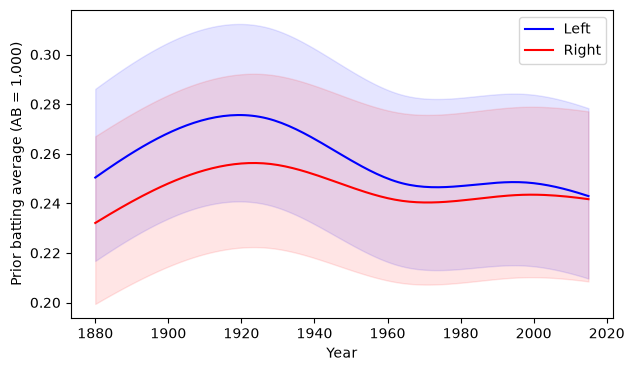

In [31]:
L2 = np.asarray(patsy.build_design_matrices([e.design_info], lefties)[0])
R2 = np.asarray(patsy.build_design_matrices([e.design_info], righties)[0])

for side, color, hand in zip([L2, R2], ['blue', 'red'], ["Left", "Right"]):
    m = side @ spline_fit2[0:-1]
    aside, bside = to_alpha_beta(m, spline_fit2[-1])
    low = stats.beta(aside, bside).ppf(0.025)
    high = stats.beta(aside, bside).ppf(0.975)
    plt.plot(yrs, stats.beta(aside, bside).ppf(0.5), color = color, label = hand)
    plt.fill_between(yrs, low, high, color=color, alpha=0.1)
plt.legend()
plt.xlabel("Year")
plt.ylabel("Prior batting average (AB = 1,000)")
plt.show()

**7.5.2 · Reflect.** What happened to the left/right gap over time? Give one possible explanation from the game itself.

*7.5.2 · Your answer:*

## 6. Posteriors for the 30/100 batters

**7.6.1 · Your turn.** For a left- and a right-handed batter with 30 H / 100 AB in 1915, 1965 and 2015, compute the prior μ, α₀, β₀ and posterior α₁, β₁ from the interaction model. Plot the six posteriors.

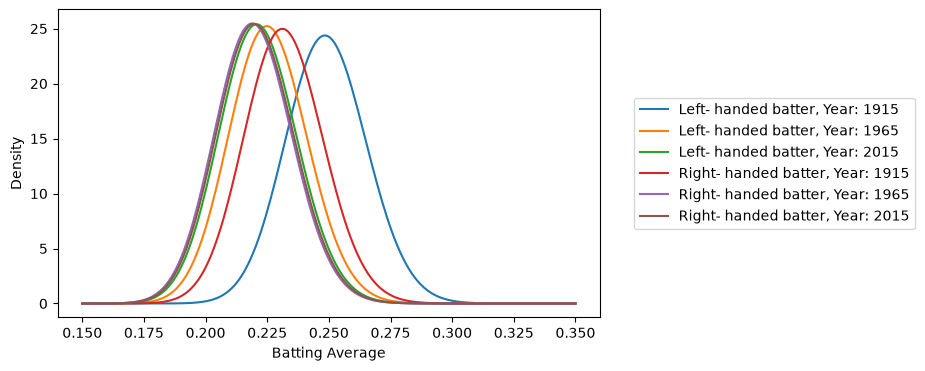

In [32]:
# 7.6.1 · Your code here
grid = pd.DataFrame({
    'year':[1915, 1965, 2015] * 2,
    'H' : 30,
    'AB' : 100,
    'is_B' : 0,
    'is_L' : [1] * 3 + [0] * 3})
f = np.asarray(patsy.build_design_matrices([e.design_info], grid)[0])
grid['mu_prior'] = f @ spline_fit2[0:-1]
grid['a0'], grid['b0'] = to_alpha_beta(grid['mu_prior'], spline_fit2[-1])
grid['a1'] = grid.a0 + grid.H
grid['b1'] = grid.b0 + grid.AB - grid.H
grid.head()

x = np.linspace(0.15, 0.35, 200)
for aa, bb, yr, hand in zip(grid.a1, grid.b1, grid.year, ["Left"] * 3 + ["Right"] * 3):
    # print(aa, bb, yr, hand)
    plt.plot(x, stats.beta(aa, bb).pdf(x), label = f"{hand}- handed batter, Year: {yr}")
plt.xlabel("Batting Average")
plt.ylabel("Density")
plt.legend(bbox_to_anchor=(1.05, 0.5), loc="center left")
plt.show()

> **Check:** prior μ for L / R is about 0.230 / 0.211 in 1915, 0.208 / 0.201 in 1965, and 0.212 / 0.212 in 2015.

**7.6.2 · Your turn.** Using a method from Lesson 05, compute P(lefty better than righty) in each of the three years.

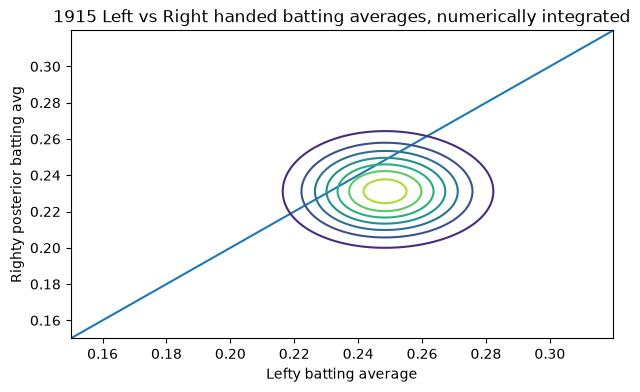

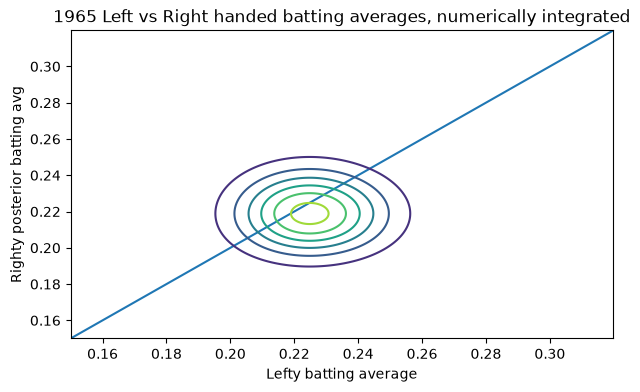

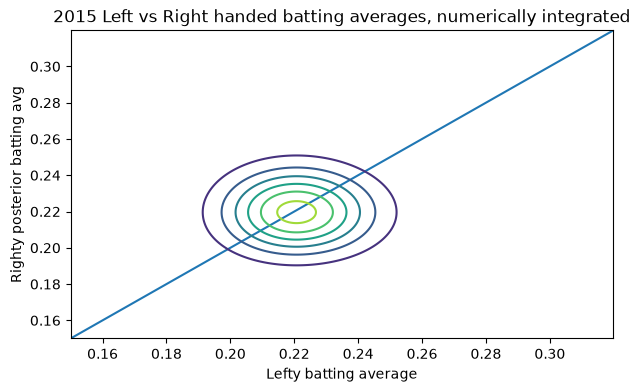

Year: 1915, P(Left > Right BA): 0.7728119000183485
Year: 1965, P(Left > Right BA): 0.6034007754962984
Year: 2015, P(Left > Right BA): 0.5173622928553517


In [33]:
# 7.6.2 · Your code here

spacing = 0.0002
start = 0.15
stop = 0.32
yrs = [1915, 1965, 2015]
LvsRs = []


def numint(AA, BA, AB, BB, stt, stp, space):
    x = np.arange(stt, stp, space)
    y = np.arange(stt, stp, space)
    X, Y = np.meshgrid(x, y)
    Z = []
    Z = (stats.beta(AB, BB).pdf(X)) * (stats.beta(AA, BA).pdf(Y))
    p_BmoreA = np.sum(Z * (X > Y))*(space ** 2)
    return(p_BmoreA, x, y, X, Y, Z)
    
for yr, row in zip(yrs, [0, 1, 2]):
    #in this case, to get L vs R (and not R vs L), right is processed first on y axis, left processed second on x axis
    left = grid[(grid['year'] == yr) & (grid['is_L'] == True)]
    right = grid[(grid['year'] == yr) & (grid['is_L'] == False)]
    alphabetas = [right.a1, right.b1, left.a1, left.b1,]
    (p_LvsR, x, y, X, Y, Z) = numint(*alphabetas, start, stop, spacing)
    plt.plot(x, y)
    plt.contour(X, Y, Z)
    plt.xlabel("Lefty batting average")
    plt.ylabel("Righty posterior batting avg")
    plt.title(f"{yr} Left vs Right handed batting averages, numerically integrated")
    plt.show()
    LvsRs.append(p_LvsR)

for y, p in zip(yrs, LvsRs):
    print(f"Year: {y}, P(Left > Right BA): {p}")

## 7. Uncertainty in the hyperparameters

Empirical Bayes treats every fitted coefficient as known exactly, even though each came from the same data (*double-dipping*). With a handful of parameters and 10,000 players that's harmless. With dozens of coefficients, some of them weakly determined, it starts to matter.

**7.7.1 · Your turn.** Get standard errors for the interaction model's coefficients from the inverse Hessian. Which coefficients are least certain?

In [ ]:
# 7.7.1 · Your code heret

**7.7.2 · Reflect.** How many hyperparameters does the interaction model have? Which conclusions in this lesson would you trust less because the model ignores their uncertainty? Lesson 13 fits the same kind of model with full Bayes.

*7.7.2 · Your answer:*

## References

- *Introduction to Empirical Bayes: Examples from Baseball Statistics*, David Robinson (2017), Chapter 8.
- patsy splines: https://patsy.readthedocs.io/en/latest/spline-regression.html
- McElreath, *Statistical Rethinking* (2nd ed.), Chapter 4 (splines) and Chapter 13 (multilevel models).